$$\begin{align} \underset{\mathbf z}{\mathbf{Max}} \quad \underset{\boldsymbol y}{\mathbf{Min}} \quad \underset{\mathbf x}{\mathbf{Max}} \quad& x_{ts} \\ \text{s.t.}\quad & z\in\mathcal Z  \\  & y\in\mathcal Y(z) \\ &x_{ij} \leq u_{ij}\phi_{ij}(1-y_i)(1-y_j) &&\forall\ (i,j)\in E \\ &\sum_{(i,j)\in E}x_{ij} - \sum_{(j,i)\in E}x_{ji}=0 &&\forall\ i\in N\setminus\{s,t\} \\ &\sum_{(s,j)\in E}x_{sj} - \sum_{(j,s)\in E}x_{js}=x_{ts} \\ &\sum_{(j,t)\in E}x_{jt} - \sum_{(t,j)\in E}x_{tj}=x_{ts} \\ &x_{ij}\geq0 &&\forall\ (i,j)\in E.  \end{align}$$


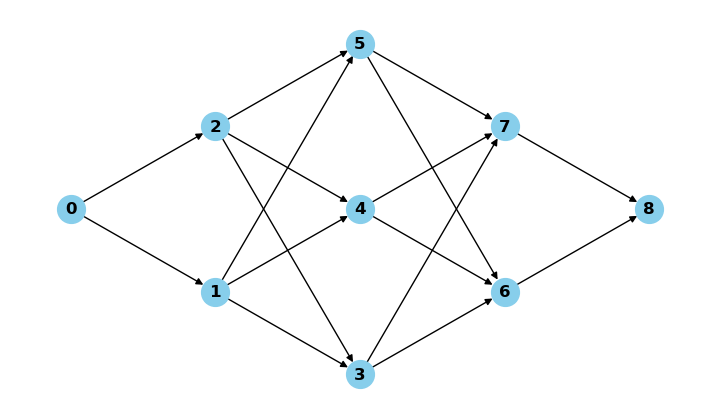

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

G = nx.complete_multipartite_graph(1,2,3,2,1).to_directed()
subset = nx.get_node_attributes(G, 'subset')
G.remove_edges_from([(u,v) for u,v in G.edges if subset[v]-subset[u] != 1])
pos = nx.multipartite_layout(G)
plt.figure(figsize=(7,4))
nx.draw(G, pos, node_color='skyblue', font_weight='bold', with_labels=True, node_size=400)

np.random.seed(123)
for u,v,d in G.edges(data=True):
    d['leader_cost'] = np.random.uniform(2, 5)
    d['capacity'] = np.random.randint(1, 5)

for n,d in G.nodes(data=True):
    d['follower_cost'] = np.random.uniform(5, 10)

In [2]:
"""
model.sink = pyo.Constraint(rule=self.r.sink_flow_rule)
model.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
Objectives.apply('max_flow', model)
return model
"""

"\nmodel.sink = pyo.Constraint(rule=self.r.sink_flow_rule)\nmodel.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)\nObjectives.apply('max_flow', model)\nreturn model\n"

In [7]:
from pyomo import environ as pyo

class TriLevel:
    def __init__(self, G:nx.DiGraph, solver_str:str='appsi_highs'):
        self.g = G
        self.solver_str = solver_str
        self.leader_costs = nx.get_edge_attributes(self.g, 'leader_cost')
        self.follower_costs = nx.get_node_attributes(self.g, 'follower_cost')
        self.capacity = nx.get_edge_attributes(self.g, 'capacity')
        self._configure_artifical_nodes()
        self._initialize_model()

    def solve_model(self):
        self.solver = pyo.SolverFactory(self.solver_str)
        self.result = self.solver.solve(self.model)

    def _configure_artifical_nodes(self, source='s', sink='t', M=1000):
        self.g.add_node(source, demand=0, subset=-1, artificial=True, follower_cost=1+sum(self.follower_costs.values()))
        subset_max = max(d['subset'] for _,d in self.g.nodes(data=True))
        self.g.add_node(sink, demand=0, subset=1+subset_max, artificial=True, follower_cost=1+sum(self.follower_costs.values()))
        for n, d in self.g.nodes(data=True):
            if d['subset'] == 0:
                self.g.add_edge(source, n, capacity=1+sum(self.capacity.values()), leader_cost=0)
            elif d['subset'] == subset_max:
                self.g.add_edge(n, sink, capacity=1+sum(self.capacity.values()), leader_cost=0)

    def _initialize_model(self):
        self.model = pyo.ConcreteModel()
        model = self.model
        model.nodes = pyo.Set(initialize=list(self.g.nodes()))
        model.edges = pyo.Set(initialize=list(self.g.edges()), dimen=2)
        model.s = 's'
        model.t = 't'

        model.capacity = pyo.Param(model.edges,initialize={(u, v): self.g.edges[u, v]['capacity'] for u, v in self.g.edges()})
        model.leader_cost = pyo.Param(model.edges,initialize={(u, v): self.g.edges[u, v]['leader_cost'] for u, v in self.g.edges()})
        model.follower_cost = pyo.Param(model.nodes,initialize={n: self.g.nodes[n]['follower_cost'] for n in self.g.nodes()})

        model.z = pyo.Var(model.edges, within=pyo.Binary) # Leader invests
        model.y = pyo.Var(model.nodes, within=pyo.Binary) # Follower blocks
        model.x = pyo.Var(model.edges, within=pyo.NonNegativeReals) # Leader maximizes
        model.F = pyo.Var(within=pyo.NonNegativeReals) # Max flow objective function term

        self._objective_function()
        self._constraints()

    def _objective_function(self):
        self.model.objective = pyo.Objective(expr=self.model.F, sense=pyo.maximize)

    def _constraints(self):
        model = self.model
        model.flow_capacity_i = pyo.Constraint(model.edges, rule=self.flow_capacity_i_rule)
        model.flow_capacity_j = pyo.Constraint(model.edges, rule=self.flow_capacity_j_rule)
        model.edge_flow = pyo.Constraint(model.nodes, rule=self.edge_flow_rule)
        model.source_flow = pyo.Constraint(rule=self.source_flow_rule)
        model.sink_flow = pyo.Constraint(rule=self.sink_flow_rule)


    @staticmethod
    def flow_capacity_i_rule(m, i, j):
        return m.x[i, j] <= m.capacity[i, j] * (1 - m.y[i])

    @staticmethod
    def flow_capacity_j_rule(m, i, j):
        return m.x[i, j] <= m.capacity[i, j] * (1 - m.y[j])

    @staticmethod
    def edge_flow_rule(m:pyo.ConcreteModel, n:pyo.Param) -> pyo.Constraint:
        """Flow conservation for all non-artificial nodes"""
        if n in (m.s, m.t):
            return pyo.Constraint.Skip
        inflow = sum(m.x[u, v] for (u, v) in m.edges if v == n)
        outflow = sum(m.x[u, v] for (u, v) in m.edges if u == n)
        return inflow == outflow
    
    @staticmethod
    def source_flow_rule(m:pyo.ConcreteModel) -> pyo.Constraint:
        """Controls flow from artificial source s"""
        outflow = sum(m.x[u, v] for (u, v) in m.edges if u == m.s)
        inflow = sum(m.x[u, v] for (u, v) in m.edges if v == m.s)
        return outflow - inflow == m.F
    
    @staticmethod
    def sink_flow_rule(m:pyo.ConcreteModel) -> pyo.Constraint:
        """Controls flow to artificial terminus t"""
        inflow = sum(m.x[u, v] for (u, v) in m.edges if v == m.t)
        outflow = sum(m.x[u, v] for (u, v) in m.edges if u == m.t)
        return inflow - outflow == m.F


In [4]:
capacity = sum(nx.get_edge_attributes(G, 'capacity').values())
capacity

36

In [5]:
nx.get_node_attributes(G, 'subset')

{0: 0, 1: 1, 2: 1, 3: 2, 4: 2, 5: 2, 6: 3, 7: 3, 8: 4}

In [8]:
model = TriLevel(G)
model.solve_model()

In [9]:
model.result

{'Problem': [{'Lower bound': 3.0, 'Upper bound': 3.0, 'Number of objectives': 1, 'Number of constraints': 0, 'Number of variables': 0, 'Sense': 'maximize'}], 'Solver': [{'Status': 'ok', 'Termination condition': 'optimal', 'Termination message': 'TerminationCondition.optimal'}]}